In [21]:
# Untuk Pengolahan Kata

from transformers import pipeline
import emoji
import re
import nltk
from nltk.corpus import stopwords, words
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from transformers import pipeline

# Untuk pre processing data
from sklearn.model_selection import train_test_split

# Untuk Pemodelan
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

# Untuk Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import numpy as np
import pandas as pd
import torch 

import os

In [2]:
df = pd.read_csv(f"D:/KULIAH/SEMESTER VII/Pemrosesan Teks dan Suara Bahasa Alami/ANALISIS SENTIMEN/Sentiment_Analysis/Scrapping/playstore/reviews_disneyplus.csv")

In [3]:
df

,Nama,Rating,Komentar,Tanggal
0,Gatot Aryanto,1,"pas download ulang akun malah ilang, padahal s...",2026-11-22 14:25:37
1,Unangnirwana. Pribadi,5,assalamualaikum selamat siang ya sahabatku yg ...,2026-11-22 13:05:19
2,Boysamsung Note4,1,1. Nama dan model perangkat yang digunakan : P...,2026-11-22 13:02:32
3,Azkia Khn,1,kok udh gk ad kecepatan buat mutar vidio? tolo...,2026-11-22 12:45:59
4,Andhi Setiawan,2,semakin ga jelas aplikasinya buang buang duit,2026-11-22 11:46:02
...,...,...,...,...
1277,Nizal Fadliannur,1,Cara masuk nya gimana?,2020-06-09 17:57:21
1278,Nur dan Sherly,1,Masa masukin email gk bisa bisa sih...ih,2020-05-09 00:29:29
1279,Pengguna Google,4,Pls Make This Apps Available In Indonesia Pls,2020-03-30 18:15:59
1280,Pengguna Google,3,Eman,2020-01-26 00:16:29


In [4]:
### Proses EDA

In [5]:
print(df.isna().sum())
print(df.isnull().sum())
print(df.duplicated().sum())

Nama        0
Rating      0
Komentar    0
Tanggal     0
dtype: int64
Nama        0
Rating      0
Komentar    0
Tanggal     0
dtype: int64
0


In [6]:
df.drop_duplicates(inplace=True)
df = df.replace(r'^\s*$', np.nan, regex=True)  # Hapus kolom yang semua nilainya NaN
df

,Nama,Rating,Komentar,Tanggal
0,Pengguna Google,1,Adminya edan,2025-03-27 16:10:41
1,Pengguna Google,1,aplikasi keuangan terburuk. sering eror dan ga...,2025-03-27 15:53:31
2,Pengguna Google,2,pusat bantuan gak jelas,2025-03-27 15:52:27
3,Pengguna Google,1,gak bisa Upgrade ke akun premier,2025-03-27 15:41:02
4,Pengguna Google,1,"aplikasi sangat sulit dibuka, loading mulu",2025-03-27 15:32:36
...,...,...,...,...
274495,Pengguna Google,5,Bagus bgtt,2021-01-06 20:21:07
274496,Pengguna Google,5,Sangat membantu..,2021-01-06 20:16:49
274497,Pengguna Google,1,Apa apaan ini ko gak bisa masuk akun gagal terus,2021-01-06 20:06:11
274498,Pengguna Google,2,Awal nya aplikasi ini bagus tapi waktu update ...,2021-01-06 20:05:32


In [7]:
df.dropna(subset=['Komentar'], inplace=True)
df

,Nama,Rating,Komentar,Tanggal
0,Pengguna Google,1,Adminya edan,2025-03-27 16:10:41
1,Pengguna Google,1,aplikasi keuangan terburuk. sering eror dan ga...,2025-03-27 15:53:31
2,Pengguna Google,2,pusat bantuan gak jelas,2025-03-27 15:52:27
3,Pengguna Google,1,gak bisa Upgrade ke akun premier,2025-03-27 15:41:02
4,Pengguna Google,1,"aplikasi sangat sulit dibuka, loading mulu",2025-03-27 15:32:36
...,...,...,...,...
274495,Pengguna Google,5,Bagus bgtt,2021-01-06 20:21:07
274496,Pengguna Google,5,Sangat membantu..,2021-01-06 20:16:49
274497,Pengguna Google,1,Apa apaan ini ko gak bisa masuk akun gagal terus,2021-01-06 20:06:11
274498,Pengguna Google,2,Awal nya aplikasi ini bagus tapi waktu update ...,2021-01-06 20:05:32


In [8]:
print(df.isna().sum())
print(df.isnull().sum())
print(df.duplicated().sum())

Nama        0
Rating      0
Komentar    0
Tanggal     0
dtype: int64
Nama        0
Rating      0
Komentar    0
Tanggal     0
dtype: int64
0


Labeling dengan data rating

In [8]:
def map_rating_to_sentiment(rating):
  """Memetakan rating numerik ke label sentimen.

  Args:
    rating: Nilai rating (misalnya, 1-5).

  Returns:
    Label sentimen ("positive", "negative", atau "neutral").
  """
  if rating < 3:
    return "negative"
  elif rating == 3:
    return "neutral"
  else:
    return "positive"

# Terapkan fungsi pada kolom 'Rating' dan simpan hasilnya di kolom baru 'Sentiment'
df['Sentiment'] = df['Rating'].apply(map_rating_to_sentiment)

print(df)

                       Nama  Rating  \
0             Gatot Aryanto       1   
1     Unangnirwana. Pribadi       5   
2          Boysamsung Note4       1   
3                 Azkia Khn       1   
4            Andhi Setiawan       2   
...                     ...     ...   
1277       Nizal Fadliannur       1   
1278         Nur dan Sherly       1   
1279        Pengguna Google       4   
1280        Pengguna Google       3   
1281        Pengguna Google       5   

                                               Komentar              Tanggal  \
0     pas download ulang akun malah ilang, padahal s...  2026-11-22 14:25:37   
1     assalamualaikum selamat siang ya sahabatku yg ...  2026-11-22 13:05:19   
2     1. Nama dan model perangkat yang digunakan : P...  2026-11-22 13:02:32   
3     kok udh gk ad kecepatan buat mutar vidio? tolo...  2026-11-22 12:45:59   
4         semakin ga jelas aplikasinya buang buang duit  2026-11-22 11:46:02   
...                                                

In [9]:
sentiment_counts = df['Sentiment'].value_counts()
print(sentiment_counts)

Sentiment
negative    1017
positive     190
neutral       75
Name: count, dtype: int64


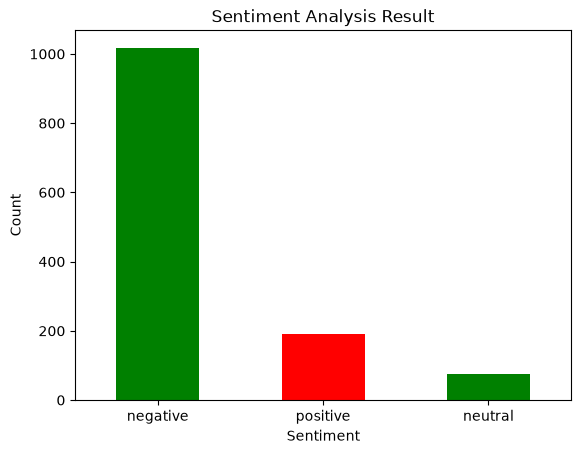

In [10]:
# Plot jumlah sentimen
sentiment_counts.plot(kind="bar", color=["green", "red"])
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.title("Sentiment Analysis Result")
plt.xticks(rotation=0)
plt.show()

In [13]:
nltk.download("punkt_tab")
nltk.download("stopwords")
stopwords_kustom = {
    "aja", "ga", "gk", "gak", "udah", "udh", "ok", "lah", "sih", "banget", "bgt",
    "cuma", "lagi", "tp", "dr", "krn", "dgn", "yg", "tdk", "blm", "sm", "sdh", "mn", 
    "jg", "sy", "sya", "gw", "gue", "nya", "ya"
}
    
def bersihkan_teks(teks):
    if isinstance(teks, str):
        teks = teks.lower()
        teks = re.sub(r'[^\w\s]', '', teks)
        kata_kata = word_tokenize(teks)

        # Ambil stopword dari bahasa Indonesia dan Inggris
        stop_words_ind = set(stopwords.words('indonesian'))
        stop_words_eng = set(stopwords.words('english'))

        # Gabungkan semua stopword
        stop_words = stop_words_ind.union(stop_words_eng).union(stopwords_kustom)

        # Hapus stopword
        kata_kata = [kata for kata in kata_kata if kata not in stop_words]
        return kata_kata
    else:
        return []

df['Kata_Bersih'] = df['Komentar'].apply(bersihkan_teks)


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [14]:
print(df.isna().sum())
print(df.isnull().sum())

Nama           0
Rating         0
Komentar       0
Tanggal        0
Sentiment      0
Kata_Bersih    0
dtype: int64
Nama           0
Rating         0
Komentar       0
Tanggal        0
Sentiment      0
Kata_Bersih    0
dtype: int64


In [17]:
df["Kata_Bersih"] = df["Kata_Bersih"].apply(lambda x: " ".join(x) if isinstance(x, list) else str(x))
print(df.duplicated().sum())

0


Label dengan BERT

In [24]:
sentiment_pipeline = pipeline("text-classification", model="indobenchmark/indobert-base-p1")
# Fungsi untuk menganalisis sentimen pada setiap teks
def analyze_sentiment(text):
    if isinstance(text, str):  # Pastikan teks bukan NaN
        result = sentiment_pipeline(text)[0]
        return result["label"]
    return "Neutral"

# Terapkan ke kolom 'cleaned_text'
df["Sentimen"] = df["Kata_Bersih"].apply(analyze_sentiment)


NameError: name 'torch' is not defined

In [14]:
df['Sentimen'] = df['Kata_Bersih'].apply(label_sentimen_duafile)

In [15]:
sentiment_count = df['Sentimen'].value_counts()
print(sentiment_count)

Sentimen
netral    274494
Name: count, dtype: int64


In [25]:
# Hitung frekuensi kata untuk setiap sentimen dengan split()
kata_positif = Counter([kata for daftar_kata in df[df['Sentiment'] == 'positive']['Kata_Bersih'] for kata in daftar_kata.split()])
kata_negatif = Counter([kata for daftar_kata in df[df['Sentiment'] == 'negative']['Kata_Bersih'] for kata in daftar_kata.split()])

Visualisasi Kata yang sering muncul

In [26]:
print("\nKata-kata umum dalam sentimen negatif:")
kata_negatif.most_common(50)


Kata-kata umum dalam sentimen negatif:


[('aplikasi', 298),
 ('login', 285),
 ('disney', 154),
 ('langganan', 139),
 ('tv', 131),
 ('masuk', 124),
 ('update', 107),
 ('nonton', 105),
 ('akun', 101),
 ('apk', 93),
 ('bahasa', 92),
 ('subtitle', 86),
 ('berlangganan', 84),
 ('susah', 84),
 ('jelek', 80),
 ('ribet', 78),
 ('indonesia', 71),
 ('gabisa', 65),
 ('paket', 65),
 ('app', 65),
 ('film', 63),
 ('log', 62),
 ('bayar', 58),
 ('pakai', 56),
 ('telkomsel', 56),
 ('hp', 55),
 ('pake', 55),
 ('bagus', 54),
 ('pas', 50),
 ('download', 49),
 ('tolong', 48),
 ('daftar', 47),
 ('email', 44),
 ('ulang', 42),
 ('ganti', 42),
 ('buka', 40),
 ('1', 39),
 ('otp', 39),
 ('error', 38),
 ('beli', 38),
 ('kode', 35),
 ('kali', 35),
 ('suruh', 33),
 ('perbaiki', 32),
 ('sampah', 31),
 ('coba', 31),
 ('bikin', 31),
 ('audio', 31),
 ('aplikasinya', 30),
 ('aneh', 29)]

In [27]:
print("\nKata-kata umum dalam sentimen positif:")
kata_positif.most_common(50)


Kata-kata umum dalam sentimen positif:


[('disney', 38),
 ('bagus', 29),
 ('good', 14),
 ('aplikasi', 12),
 ('indonesia', 12),
 ('mantap', 11),
 ('app', 11),
 ('hotstar', 10),
 ('subtitle', 9),
 ('film', 9),
 ('login', 8),
 ('tv', 8),
 ('masuk', 8),
 ('bahasa', 8),
 ('tolong', 8),
 ('aplikasinya', 7),
 ('langganan', 7),
 ('download', 7),
 ('keren', 7),
 ('lancar', 6),
 ('nonton', 6),
 ('oke', 6),
 ('movies', 6),
 ('pake', 6),
 ('suka', 5),
 ('mudah', 5),
 ('apps', 5),
 ('entertainment', 5),
 ('update', 5),
 ('akun', 5),
 ('menonton', 4),
 ('hp', 4),
 ('apk', 4),
 ('best', 4),
 ('streaming', 4),
 ('bayar', 4),
 ('berlangganan', 4),
 ('ganti', 4),
 ('kadang', 4),
 ('versi', 4),
 ('marvel', 4),
 ('pakai', 4),
 ('konten', 4),
 ('indonesian', 4),
 ('kasih', 3),
 ('tambahkan', 3),
 ('warna', 3),
 ('susah', 3),
 ('knapa', 3),
 ('movie', 3)]

C:\Users\HP\AppData\Local\Temp\ipykernel_8280\1882581297.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frekuensi', y='Kata', data=df_positif, palette='Blues_r')
C:\Users\HP\AppData\Local\Temp\ipykernel_8280\1882581297.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frekuensi', y='Kata', data=df_negatif, palette='Reds_r')


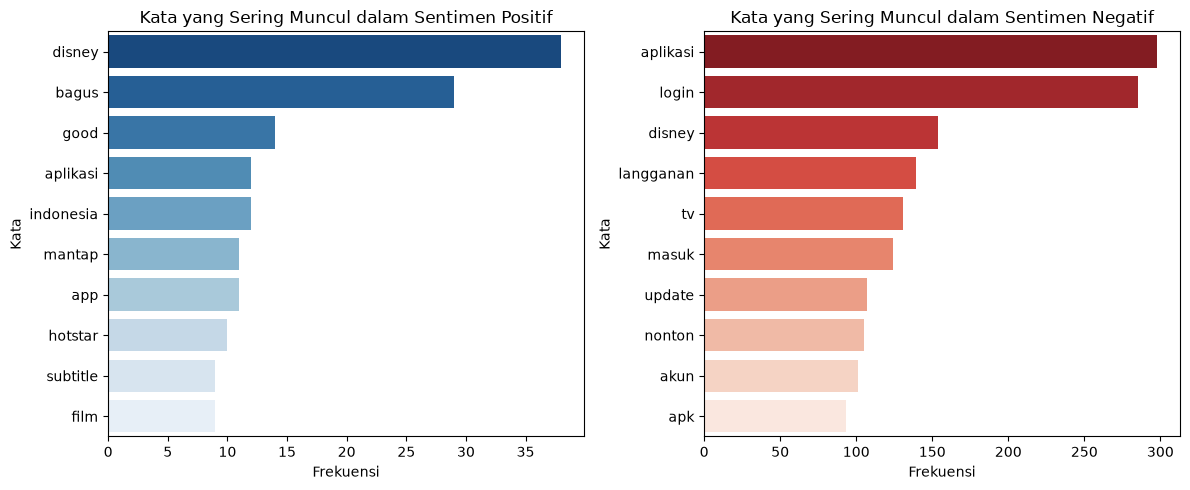

In [28]:
# Konversi ke DataFrame untuk visualisasi
df_positif = pd.DataFrame(kata_positif.most_common(10), columns=['Kata', 'Frekuensi'])
df_negatif = pd.DataFrame(kata_negatif.most_common(10), columns=['Kata', 'Frekuensi'])

# Plot bar chart untuk kata-kata dalam sentimen positif
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.barplot(x='Frekuensi', y='Kata', data=df_positif, palette='Blues_r')
plt.title('Kata yang Sering Muncul dalam Sentimen Positif')
plt.xlabel('Frekuensi')
plt.ylabel('Kata')

# Plot bar chart untuk kata-kata dalam sentimen negatif
plt.subplot(1, 2, 2)
sns.barplot(x='Frekuensi', y='Kata', data=df_negatif, palette='Reds_r')
plt.title('Kata yang Sering Muncul dalam Sentimen Negatif')
plt.xlabel('Frekuensi')
plt.ylabel('Kata')

# Tampilkan plot
plt.tight_layout()
plt.show()

In [18]:
# Ubah kolom Tanggal menjadi format datetime
df["Tanggal"] = pd.to_datetime(df["Tanggal"])

# Mengelompokkan jumlah komentar berdasarkan tanggal
df_grouped = df.groupby(df["Tanggal"].dt.date).size().reset_index(name="Jumlah Komentar")

# Menampilkan tabel hasil
print(df_grouped)

         Tanggal  Jumlah Komentar
0     2021-01-06               44
1     2021-01-07              200
2     2021-01-08              161
3     2021-01-09              167
4     2021-01-10              122
...          ...              ...
1515  2025-03-23              109
1516  2025-03-24              108
1517  2025-03-25              413
1518  2025-03-26              171
1519  2025-03-27               67

[1520 rows x 2 columns]


In [19]:
df['Kata_Bersih'] = df['Kata_Bersih'].astype(str)

# Mengecek jumlah data yang duplikat
df.duplicated().sum()

0

### Ekstraksi Fitur (Feature Engineering)

#### TF-IDF (Term Frequency - Inverse Documents Frequency)

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Target label (sentimen)
y = df["Sentiment"].map({"positive": 1, "negative": 0})
y = y.dropna()
df = df.loc[y.index] 

tfidf_vectorizer = TfidfVectorizer(max_features=1000)
X_tfidf = tfidf_vectorizer.fit_transform(df["Kata_Bersih"]).toarray()


# Lihat fitur TF-IDF
print(tfidf_vectorizer.get_feature_names_out()[:20])


['10' '2026' '21' '2x' '4k' '62' 'acara' 'account' 'ad' 'add' 'address'
 'admin' 'aga' 'ah' 'aj' 'ajaa' 'akibatnya' 'akses' 'aktif' 'aktifkan']


In [31]:
import pickle

# Simpan TF-IDF vectorizer
with open("tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf_vectorizer, f)

### Word to Vectors (Word2vec)

In [32]:
import gensim
from gensim.models import Word2Vec

# Tokenisasi teks menjadi list kata
df["Kata_Token"] = df["Kata_Bersih"].apply(lambda x: x.split())

# Pelatihan model Word2Vec
model_w2v = Word2Vec(sentences=df["Kata_Token"], vector_size=100, window=5, min_count=1, workers=4)

# Fungsi untuk mendapatkan vektor kalimat dengan merata-rata vektor kata
def get_sentence_vector(sentence, model):
    words = sentence.split()
    word_vectors = [model.wv[word] for word in words if word in model.wv]
    return np.mean(word_vectors, axis=0) if word_vectors else np.zeros(model.vector_size)

# Transformasi teks menjadi vektor Word2Vec
X_w2v = np.array([get_sentence_vector(text, model_w2v) for text in df["Kata_Bersih"]])


ModuleNotFoundError: No module named 'gensim'

In [ ]:
# Simpan model Word2Vec ke file
model_w2v.save("model_w2v.model")

### Modelling Dengan Machine Learning atau Deep Learning

#### Splitting data

In [33]:
from sklearn.model_selection import train_test_split

X_train_tf, X_test_tf, y_train_tf, y_test_tf = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

In [38]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_tf, y_train_tf)

In [34]:
# Pembagian data menjadi training dan testing
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(X_w2v, y, test_size=0.2, random_state=42)

NameError: name 'X_w2v' is not defined

### Melatih Model Machine Learning

#### Model Naive Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Buat model Naive Bayes
model_nb = MultinomialNB(alpha=5.0)
model_nb.fit(X_train_res, y_train_res)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",5.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[811.,154.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.17,-1.84]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 1000)","[[0.58,1.27,2.33,...,1.37,0.94,0.69], [0. ,0. ,0. ,...,0.42,0.47,0.25]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 1000)","[[-7.12,-7. ,-6.84,...,-6.99,-7.06,-7.1 ], [-6.95,-6.95,-6.95,...,-6.87,-6.86,-6.9 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1000


Evaluasi model Naive Bayes

In [36]:
from sklearn.metrics import classification_report, accuracy_score

# Prediksi pada data uji
y_pred = model_nb.predict(X_test_tf)
# Evaluasi performa model
# print("Akurasi Training:", accuracy_score(y_train_tf, ))
print("Akurasi Testing:", accuracy_score(y_test_tf, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test_tf, y_pred))

Akurasi Testing: 0.8512396694214877
Laporan Klasifikasi:
               precision    recall  f1-score   support

         0.0       0.85      1.00      0.92       206
         1.0       0.00      0.00      0.00        36

    accuracy                           0.85       242
   macro avg       0.43      0.50      0.46       242
weighted avg       0.72      0.85      0.78       242



d:\KULIAH\SEMESTER VII\Pemrosesan Teks dan Suara Bahasa Alami\ANALISIS SENTIMEN\Sentiment_Analysis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\KULIAH\SEMESTER VII\Pemrosesan Teks dan Suara Bahasa Alami\ANALISIS SENTIMEN\Sentiment_Analysis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\KULIAH\SEMESTER VII\Pemrosesan Teks dan Suara Bahasa Alami\ANALISIS SENTIMEN\Sentiment_Analysis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Prec

Confussion Matriks Naive Bayes

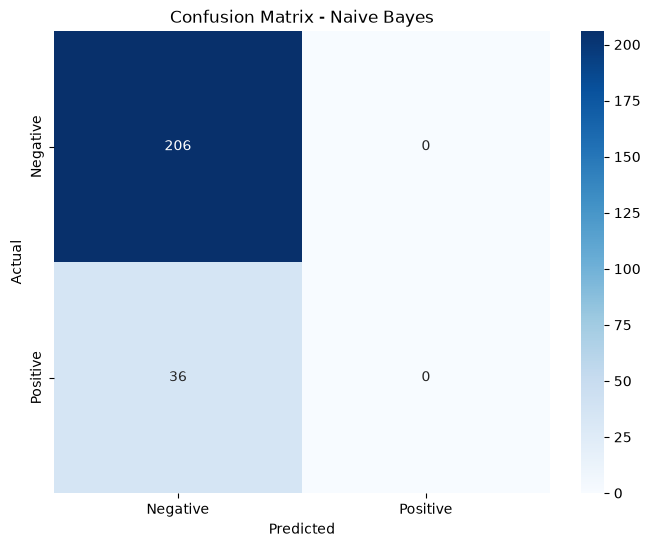

In [37]:
conf_matrix = confusion_matrix(y_test_tf, y_pred)

# Plot confussion matriks
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

Testing model Naive Bayes

In [ ]:
komentar_baru = ["Aplikasinya jelek, pelayannanya kurang!", "Saya sangat puas dengan pelayanannya."]

# Bersihkan teks & gabungkan kembali ke string
komentar_baru_bersih = [' '.join(bersihkan_teks(k)) for k in komentar_baru]

# Transformasi ke TF-IDF
X_baru = tfidf_vectorizer.transform(komentar_baru_bersih)

# Prediksi Sentimen
prediksi = model_nb.predict(X_baru)

# Tampilkan hasil
for komentar, sentimen in zip(komentar_baru, prediksi):
    print(f"Komentar: {komentar} → Sentimen: {'Positif' if sentimen == 1 else 'Negatif'}")


Komentar: Aplikasinya jelek, pelayannanya kurang! → Sentimen: Negatif
Komentar: Saya sangat puas dengan pelayanannya. → Sentimen: Positif


In [53]:
import joblib

# Simpan model ke file
joblib.dump(model_nb, 'models/model_naive_bayes.pkl')

['models/model_naive_bayes.pkl']

#### Model Linear Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=500, C=10, solver= "saga", class_weight="balanced")
model_lr.fit(X_train_tf, y_train_tf)
y_pred_lr = model_lr.predict(X_test_tf)

Evaluasi Model Logistic Regression

In [ ]:
# Evaluasi performa model
print("Akurasi:", accuracy_score(y_test_tf, y_pred_lr))
print("Laporan Klasifikasi:\n", classification_report(y_test_tf, y_pred_lr))

Akurasi: 0.9098832773878548
Laporan Klasifikasi:
               precision    recall  f1-score   support

           0       0.86      0.92      0.89     20820
           1       0.95      0.90      0.92     31612

    accuracy                           0.91     52432
   macro avg       0.90      0.91      0.91     52432
weighted avg       0.91      0.91      0.91     52432



Confussion Matrix Logistic Regression

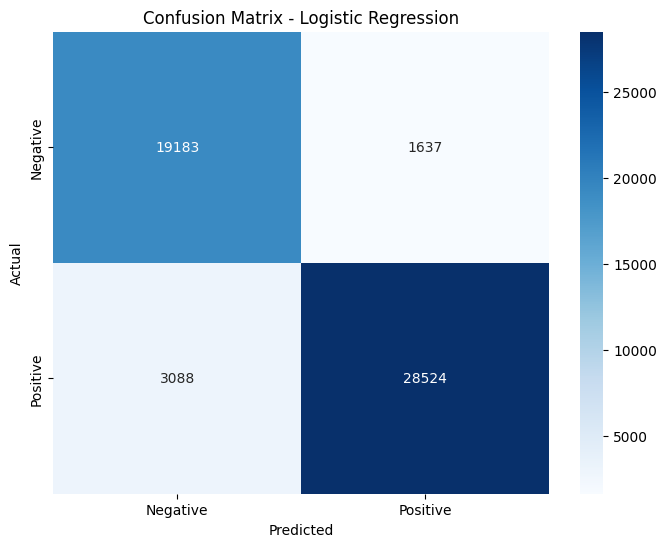

In [ ]:
# Confussion matriks Logistic Regression
conf_matrix_lr = confusion_matrix(y_test_tf, y_pred_lr)

# Plot confussion matriks
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Testing model Logistic Regression

In [ ]:
komentar_baru = ["Uang yang saya transfer telat terkirim", "Cepat banget kalo soal transfer", "aplikasinya bagus cuyy!", "Csnya gak bener sumpah, lama banget pelayanannya"]

# Bersihkan teks & gabungkan kembali ke string
komentar_baru_bersih = [' '.join(bersihkan_teks(k)) for k in komentar_baru]

# Transformasi ke TF-IDF
X_baru = tfidf_vectorizer.transform(komentar_baru_bersih)

# Prediksi Sentimen
prediksi = model_lr.predict(X_baru)

# Tampilkan hasil
for komentar, sentimen in zip(komentar_baru, prediksi):
    print(f"Komentar: {komentar} → Sentimen: {'Positif' if sentimen == 1 else 'Negatif'}")

Komentar: Uang yang saya transfer telat terkirim → Sentimen: Negatif
Komentar: Cepat banget kalo soal transfer → Sentimen: Positif
Komentar: aplikasinya bagus cuyy! → Sentimen: Positif
Komentar: Csnya gak bener sumpah, lama banget pelayanannya → Sentimen: Negatif


In [ ]:
# Simpan model ke file
joblib.dump(model_lr, 'models/model_logistic_regression.pkl')

['models/model_logistic_regression.pkl']

#### Model MLP

In [ ]:
# Model MLP
from sklearn.neural_network import MLPClassifier

# Buat model MLP
model_mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    alpha=0.5,
    batch_size=16,
    learning_rate='adaptive',
    learning_rate_init=0.0001,
    max_iter=100,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42
)
model_mlp.fit(X_train_w2v, y_train_w2v)

MLPClassifier(alpha=0.5, batch_size=16, early_stopping=True,
              hidden_layer_sizes=(32, 16), learning_rate='adaptive',
              learning_rate_init=0.0001, max_iter=100, random_state=42)

Evaluasi Model MLP

In [ ]:
# Evaluasi performa model
y_pred_mlp = model_mlp.predict(X_test_w2v)
print("Akurasi:", accuracy_score(y_test_w2v, y_pred_mlp))
print("Laporan Klasifikasi:\n", classification_report(y_test_w2v, y_pred_mlp))

Akurasi: 0.8956553249923711
Laporan Klasifikasi:
               precision    recall  f1-score   support

         0.0       0.85      0.90      0.87     20820
         1.0       0.93      0.89      0.91     31612

    accuracy                           0.90     52432
   macro avg       0.89      0.90      0.89     52432
weighted avg       0.90      0.90      0.90     52432



Confusion Matrix model MLP

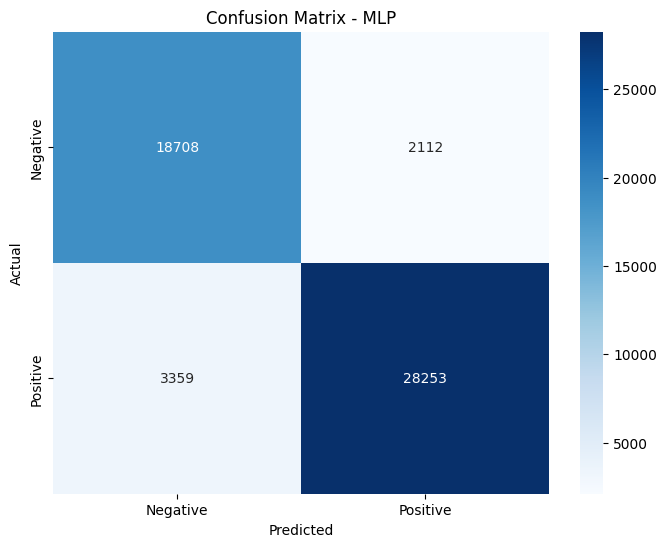

In [ ]:
# Confussion matriks mlp
conf_matrix_mlp = confusion_matrix(y_test_w2v, y_pred_mlp)

# Plot confussion matriks
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_mlp, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - MLP')
plt.show()

Testing model MLP

In [ ]:
new_texts = ["Pelayanan yang sangat baik!", 
             "jelek bnaget aplikasinya!."]
# Ubah teks menjadi vektor Word2Vec

X_new_w2v = np.array([get_sentence_vector(text, model_w2v) for text in new_texts])

# Prediksi dengan model yang telah dilatih
predictions = model_mlp.predict(X_new_w2v)

# Konversi hasil sigmoid menjadi label (0 atau 1)
predicted_labels = (predictions > 0.5).astype(int)

# Menampilkan hasil prediksi
for text, label in zip(new_texts, predicted_labels):
    sentiment = "Positif" if label == 1 else "Negatif"
    print(f"Teks: {text} -> Sentimen: {sentiment}")

Teks: Pelayanan yang sangat baik! -> Sentimen: Positif
Teks: jelek bnaget aplikasinya!. -> Sentimen: Negatif


In [ ]:
# Simpan model MLP ke file
joblib.dump(model_mlp, 'models/model_mlp.pkl')

['models/model_mlp.pkl']

### Melatih Model dengan Deep Learning

In [25]:
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

In [26]:
def create_cnn_lstm_model(input_shape):
    model = models.Sequential()
    
    # CNN Layer
    model.add(layers.Conv1D(64, kernel_size=3, activation='relu', input_shape=input_shape))
    model.add(layers.MaxPooling1D(pool_size=2))
    
    # LSTM Layer
    model.add(layers.LSTM(64))
    
    # Fully Connected Layer
    model.add(layers.Dense(32, activation='relu'))
    model.add(layers.Dropout(0.3))
    
    # Output Layer
    model.add(layers.Dense(1, activation='sigmoid'))
    
    # Compile
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    return model

cnn_lstm_model = create_cnn_lstm_model((X_train_w2v.shape[1], 1))
cnn_lstm_model.summary()

c:\Users\Sinta\anaconda3\envs\laskarai\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 98, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 49, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,393 (138.25 KB)

 Trainable params: 35,393 (138.25 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

class StopAtAccuracy(Callback):
    def __init__(self, target_acc=0.95):
        super(StopAtAccuracy, self).__init__()
        self.target_acc = target_acc

    def on_epoch_end(self, epoch, logs=None):
        acc = logs.get("val_accuracy")
        if acc is not None and acc >= self.target_acc:
            print(f"\n✅ Target val_accuracy {self.target_acc*100:.2f}% tercapai, menghentikan training...")
            self.model.stop_training = True

In [33]:
stop_acc_callback = StopAtAccuracy(target_acc=0.95) 

# Latih model
history = cnn_lstm_model.fit(
    X_train_w2v, y_train_w2v,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_w2v, y_test_w2v),
    callbacks=[lr_scheduler, early_stop, stop_acc_callback],
    verbose=1
    
)

Epoch 1/50
6554/6554 ━━━━━━━━━━━━━━━━━━━━ 210s 32ms/step - accuracy: 0.9297 - loss: 0.1931 - val_accuracy: 0.9103 - val_loss: 0.2478 - learning_rate: 1.0000e-06
Epoch 2/50
6554/6554 ━━━━━━━━━━━━━━━━━━━━ 236s 36ms/step - accuracy: 0.9300 - loss: 0.1934 - val_accuracy: 0.9103 - val_loss: 0.2478 - learning_rate: 1.0000e-06
Epoch 3/50
6554/6554 ━━━━━━━━━━━━━━━━━━━━ 324s 49ms/step - accuracy: 0.9296 - loss: 0.1958 - val_accuracy: 0.9103 - val_loss: 0.2478 - learning_rate: 1.0000e-06
Epoch 4/50
6554/6554 ━━━━━━━━━━━━━━━━━━━━ 339s 52ms/step - accuracy: 0.9297 - loss: 0.1945 - val_accuracy: 0.9103 - val_loss: 0.2478 - learning_rate: 1.0000e-06
Epoch 5/50
6554/6554 ━━━━━━━━━━━━━━━━━━━━ 420s 64ms/step - accuracy: 0.9286 - loss: 0.1947 - val_accuracy: 0.9103 - val_loss: 0.2479 - learning_rate: 1.0000e-06
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


In [39]:
cnn_lstm_model.export("models/cnn_lstm_model_tf_v2")

INFO:tensorflow:Assets written to: models/cnn_lstm_model_tf_v2\assets


INFO:tensorflow:Assets written to: models/cnn_lstm_model_tf_v2\assets


Saved artifact at 'models/cnn_lstm_model_tf_v2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 100, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2371044093792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371044181088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371044404560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371044405088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371044376640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371000031888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371000031536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371000130720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2371000130368: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [ ]:
loss, accuracy = cnn_lstm_model.evaluate(X_test_w2v, y_test_w2v)
print(f"Test Accuracy: {accuracy:.4f}")

1639/1639 [==============================] - 33s 20ms/step - loss: 0.2480 - accuracy: 0.9108
Test Accuracy: 0.9108


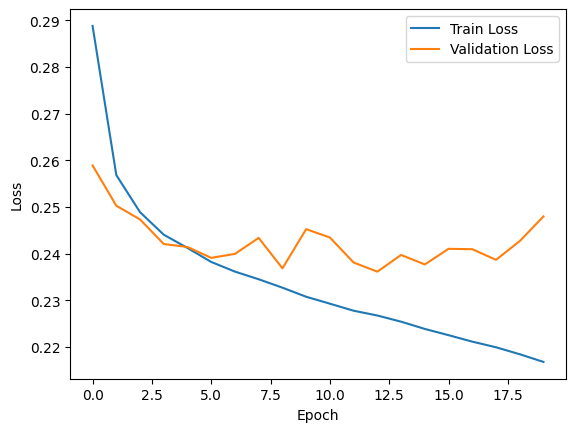

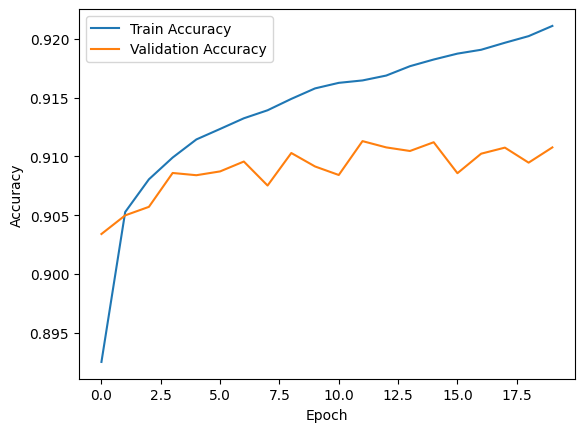

In [ ]:
# Plot loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Prediksi probabilitas
y_pred_prob = cnn_lstm_model.predict(X_test_w2v)

# Konversi probabilitas ke kelas biner (0 atau 1)
y_pred_cnn_lstm = (y_pred_prob > 0.5).astype(int)

# Classification Report
print("Laporan Klasifikasi:\n", classification_report(y_test_w2v, y_pred_cnn_lstm))

1639/1639 [==============================] - 36s 20ms/step
Laporan Klasifikasi:
               precision    recall  f1-score   support

         0.0       0.86      0.92      0.89     20820
         1.0       0.95      0.90      0.92     31612

    accuracy                           0.91     52432
   macro avg       0.90      0.91      0.91     52432
weighted avg       0.91      0.91      0.91     52432



Confusion Matrix model CNN dengan LSTM

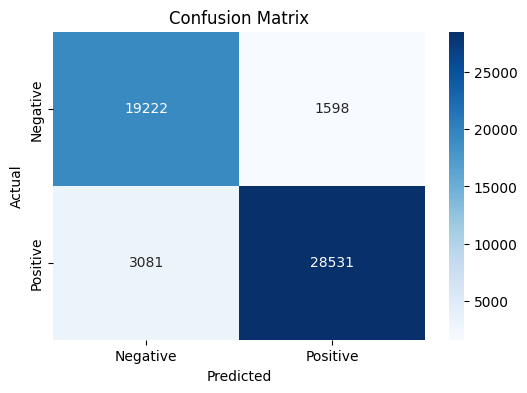

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test_w2v, y_pred_cnn_lstm)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Testing model CNN dengan LSTM

In [ ]:
new_texts = ["Pelayanan yang sangat baik!", 
             "jelek banget aplikasinya!."]
# Ubah teks menjadi vektor Word2Vec

X_new_w2v = np.array([get_sentence_vector(text, model_w2v) for text in new_texts])

# Prediksi dengan model yang telah dilatih
predictions = cnn_lstm_model.predict(X_new_w2v)

# Konversi hasil sigmoid menjadi label (0 atau 1)
predicted_labels = (predictions > 0.5).astype(int)

# Menampilkan hasil prediksi
for text, label in zip(new_texts, predicted_labels):
    sentiment = "Positif" if label == 1 else "Negatif"
    print(f"Teks: {text} -> Sentimen: {sentiment}")

1/1 [==============================] - 0s 60ms/step
Teks: Pelayanan yang sangat baik! -> Sentimen: Positif
Teks: jelek banget aplikasinya!. -> Sentimen: Negatif


In [ ]:
cnn_lstm_model.save('models/cnn_lstm_model.h5')